# Extensions: replicate-weight inference and state heterogeneity

Builds on `replication.ipynb`, which reproduced Shafer et al. (2022). Run `data_prep.ipynb` first.

**Extension (b): Census replicate-weight standard errors.** The paper (and this replication) uses state-clustered standard errors. Census recommends variance estimation with its 80 replicate weights (successive difference replication). Each model is re-estimated with each replicate weight, and

$$\text{Var}(\hat\beta) = \frac{4}{80}\sum_{r=1}^{80}\left(\hat\beta_r - \hat\beta\right)^2$$

(U.S. Census Bureau, 2021b, pp. 12-13). For pooled weeks, all weights are divided by 13.

- **Hypothesis (b):** under replicate-weight standard errors, $\beta_{34}$ remains statistically significant ($H_0: \beta_{34} = 0$, two-sided t-test, $\alpha = 0.05$, 80 degrees of freedom).
- **Descriptive:** how the replicate-weight standard errors compare with the state-clustered ones.

**Extension (a): state heterogeneity.** Does the effect of the payment differ across states? The proposal planned a mixed model with a state random slope on `kids_post`. That model failed numerically at this sample size (see the appendix), so the same hypothesis is tested with a two-stage approach: a separate DiD effect is estimated for each state in one weighted regression, with replicate-weight standard errors, and Cochran's Q test asks whether the state effects vary more than sampling error alone would produce.

- **Hypothesis (a):** the between-state variance of the effect is greater than zero ($H_0: \tau^2 = 0$, equivalent to the proposal's $\sigma^2_b = 0$), tested with Cochran's Q ($\chi^2$ with 50 degrees of freedom).
- **Descriptive:** the spread of the effect across states ($\tau$), and whether the pooled average stays close to the national DiD estimate.

## Setup

In [16]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from modules import prepare_pulse, analysis, extensions as ext

BLUE, ORANGE, INK, MUTED, GRID = "#257de0", "#f47230", "#191919", "#666666", "#e5e5e5"

a = analysis.add_model_vars(prepare_pulse.load("analytic_sample"))
assert len(a) == 585_170
a = ext.attach_replicate_weights(a)
print(f"{len(a):,} rows with {len(ext.REP_COLS)} replicate weights attached")

585,170 rows with 80 replicate weights attached


## Extension (b): replicate-weight standard errors

### Reference models (state-clustered, as in `replication.ipynb`)

In [17]:
did = analysis.fit_wls(analysis.did_formula(), a)
es = analysis.fit_wls(analysis.event_study_formula(), a)
B34 = [n for n in es.params.index if n.startswith("kids:C(WEEK") and n.endswith("[T.34]")][0]
PRE = [n for n in es.params.index if n.startswith("kids:C(WEEK") and n != B34]
print("DiD:", round(did.params["kids_post"], 4), "| beta_34:", round(es.params[B34], 4))

DiD: -0.0221 | beta_34: -0.0367


### Replicate coefficients

Each model is solved 81 times: once with the full-sample weight and once with each replicate weight. Results are cached in `data/processed/replicate_cache/`, so re-running this cell after the first time loads them instead of recomputing. The first run takes a few minutes per model.

In [18]:
did_full, did_reps = ext.replicate_coefficients(analysis.did_formula(), a, name="did")
es_full, es_reps = ext.replicate_coefficients(analysis.event_study_formula(), a, name="event_study")

# Check: full-sample coefficients from the fast solver must match statsmodels
assert np.isclose(did_full["kids_post"], did.params["kids_post"]), "DiD mismatch"
assert np.isclose(es_full[B34], es.params[B34]), "Event-study mismatch"
print("Full-sample coefficients match statsmodels.")

did: loaded cached replicate coefficients
event_study: loaded cached replicate coefficients
Full-sample coefficients match statsmodels.


### Hypothesis (b): is $\beta_{34}$ still significant?

In [19]:
rep_did = ext.replicate_inference(did_full, did_reps, ["kids_post"])
rep_es = ext.replicate_inference(es_full, es_reps, [B34])

comparison = pd.concat([
    ext.compare_se(did, rep_did, ["kids_post"]).rename(index={"kids_post": "DiD"}),
    ext.compare_se(es, rep_es, [B34]).rename(index={B34: "beta_34"}),
])
comparison.round(4)

,coef,se_cluster,p_cluster,lo_cluster,hi_cluster,se_rep,p_rep,lo_rep,hi_rep,se_ratio (rep/cluster)
DiD,-0.0221,0.006,0.0006,-0.0343,-0.0100,0.0065,0.0010,-0.0350,-0.0093,1.0744
beta_34,-0.0367,0.009,0.0002,-0.0547,-0.0187,0.0095,0.0002,-0.0556,-0.0178,1.0590


In [20]:
p = rep_es.loc[B34, "p"]
print(f"H0: beta_34 = 0 under replicate-weight SEs: t = {rep_es.loc[B34, 't']:.2f}, p = {p:.4g} (80 df)")
print("Reject H0 at alpha = 0.05:", p < 0.05)

H0: beta_34 = 0 under replicate-weight SEs: t = -3.86, p = 0.0002264 (80 df)
Reject H0 at alpha = 0.05: True


### Parallel trends under replicate weights

The same joint test as Section 4 of `replication.ipynb` (all pre-payment coefficients equal zero), using the replicate-weight covariance matrix instead of the clustered one.

In [21]:
F_rep, p_rep = ext.replicate_joint_test(es_full, es_reps, PRE)
pt_cluster = analysis.pretrend_test(es)
print(f"Pre-trend test, state-clustered: F = {float(np.squeeze(pt_cluster.fvalue)):.2f}, p = {float(pt_cluster.pvalue):.4f}")
print(f"Pre-trend test, replicate:       F = {F_rep:.2f}, p = {p_rep:.4f}")

Pre-trend test, state-clustered: F = 3.46, p = 0.0013
Pre-trend test, replicate:       F = 1.67, p = 0.0968


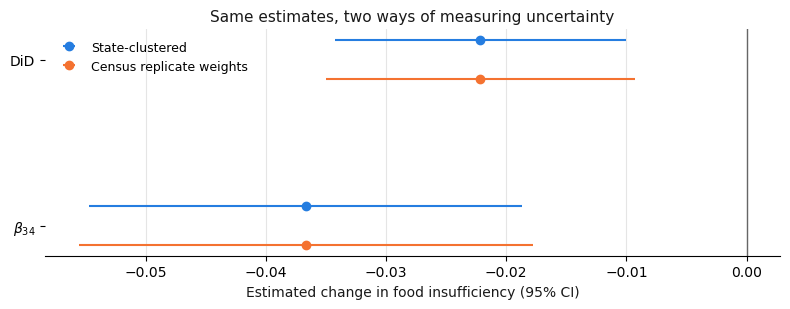

In [22]:
rows = [("DiD", "kids_post", did, rep_did), (r"$\beta_{34}$", B34, es, rep_es)]
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (label, term, fit, rep) in enumerate(rows):
    y = len(rows) - 1 - i
    lo_c, hi_c = fit.conf_int().loc[term]
    ax.errorbar(fit.params[term], y + 0.12, xerr=[[fit.params[term] - lo_c], [hi_c - fit.params[term]]],
                fmt="o", ms=6, color=BLUE, elinewidth=1.5, capsize=0, label="State-clustered" if i == 0 else None)
    ax.errorbar(rep.loc[term, "coef"], y - 0.12, xerr=[[rep.loc[term, "coef"] - rep.loc[term, "lo"]], [rep.loc[term, "hi"] - rep.loc[term, "coef"]]],
                fmt="o", ms=6, color=ORANGE, elinewidth=1.5, capsize=0, label="Census replicate weights" if i == 0 else None)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(rows)), [r[0] for r in rows][::-1])
ax.set_xlabel("Estimated change in food insufficiency (95% CI)", color=INK)
ax.set_title("Same estimates, two ways of measuring uncertainty", loc="center", color=INK, fontsize=11)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "replicate_vs_cluster_ci.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation (b).** Hypothesis (b) is supported: under Census replicate-weight standard errors, $\beta_{34}$ remains statistically significant ($\beta_{34}$ = -0.037, 95% CI -0.056 to -0.018, t = -3.86, p < .001, 80 df). The DiD estimate is also significant (-0.022, 95% CI -0.035 to -0.009, p = .001).

- **Single estimates are robust to the variance method.** Replicate-weight standard errors are 6-7% larger than state-clustered ones, widening the confidence intervals slightly without changing any conclusion.
- **The pre-trend test is not.** With state-clustered errors the joint test of the 11 pre-payment coefficients rejects parallel trends (F = 3.46, p = .001); with replicate weights it does not at the 0.05 level (F = 1.67, p = .097). Because the individual standard errors are nearly the same, the difference comes from how each method estimates the correlations among the pre-period coefficients. Cluster-robust joint tests can over-reject when many restrictions are tested with relatively few clusters (here 11 restrictions and 51 states; Cameron & Miller, 2015). The evidence against parallel trends is therefore weaker than the clustered test alone suggests, though the spring dip in the pre-period coefficients remains visible in the point estimates.

## Extension (a): state heterogeneity

### Step 1: a separate effect for each state

One weighted regression estimates a DiD effect for every state (`C(state):kids_post`), with state-specific baselines (`C(state)`) and state-specific gaps between households with and without children (`C(state):kids`), plus the usual wave fixed effects and controls. Each state's standard error comes from the 80 replicate weights, as in Extension (b).

This model has about 200 columns, so the first run needs roughly 2-3 GB of memory and a few minutes; results are cached like the others.

In [23]:
states = ext.state_slopes_replicate(a)
states["abbr"] = states["state"].map(ext.STATE_ABBR)
states[["abbr", "effect", "se_rep", "lo", "hi", "n", "n_kids_wk34"]].round(4)

state_did: loaded cached replicate coefficients


,abbr,effect,se_rep,lo,hi,n,n_kids_wk34
0,DE,-0.0746,0.0298,-0.1338,-0.0154,6299,156
1,LA,-0.0686,0.0263,-0.1210,-0.0162,6628,265
2,WV,-0.0534,0.0350,-0.1231,0.0164,5976,164
3,TX,-0.0504,0.0237,-0.0977,-0.0032,32117,968
4,NY,-0.0500,0.0246,-0.0990,-0.0010,11984,294
5,HI,-0.0499,0.0279,-0.1054,0.0055,5939,164
6,FL,-0.0461,0.0391,-0.1239,0.0316,18237,552
7,VA,-0.0455,0.0193,-0.0838,-0.0071,16132,505
8,NM,-0.0439,0.0261,-0.0959,0.0080,11190,308
9,GA,-0.0437,0.0262,-0.0957,0.0084,13252,440


### Step 2: hypothesis (a), do the state effects vary?

Cochran's Q compares how far each state's effect sits from the precision-weighted average, relative to its standard error. If every state shared one true effect, Q would follow $\chi^2$ with 50 degrees of freedom (51 states - 1). The DerSimonian-Laird method also estimates $\tau$, the standard deviation of the true effects across states (the quantity the random slope was meant to capture), and $I^2$, the share of the observed spread that reflects real differences rather than sampling error.

In [24]:
het = ext.heterogeneity_test(states["effect"], states["se_rep"])
print(f"Q = {het['Q']:.1f} on {het['df']} df, p = {het['p']:.4g}")
print(f"tau (SD of true state effects) = {het['tau']:.4f};  I^2 = {het['I2']:.1%}")
print(f"Pooled random-effects mean = {het['re_mean']:.4f} (SE {het['re_se']:.4f})   [national DiD: {did.params['kids_post']:.4f}]")
print("Reject H0 (no state variation) at alpha = 0.05:", het["p"] < 0.05)

Q = 58.4 on 50 df, p = 0.1932
tau (SD of true state effects) = 0.0101;  I^2 = 14.4%
Pooled random-effects mean = -0.0168 (SE 0.0038)   [national DiD: -0.0221]
Reject H0 (no state variation) at alpha = 0.05: False


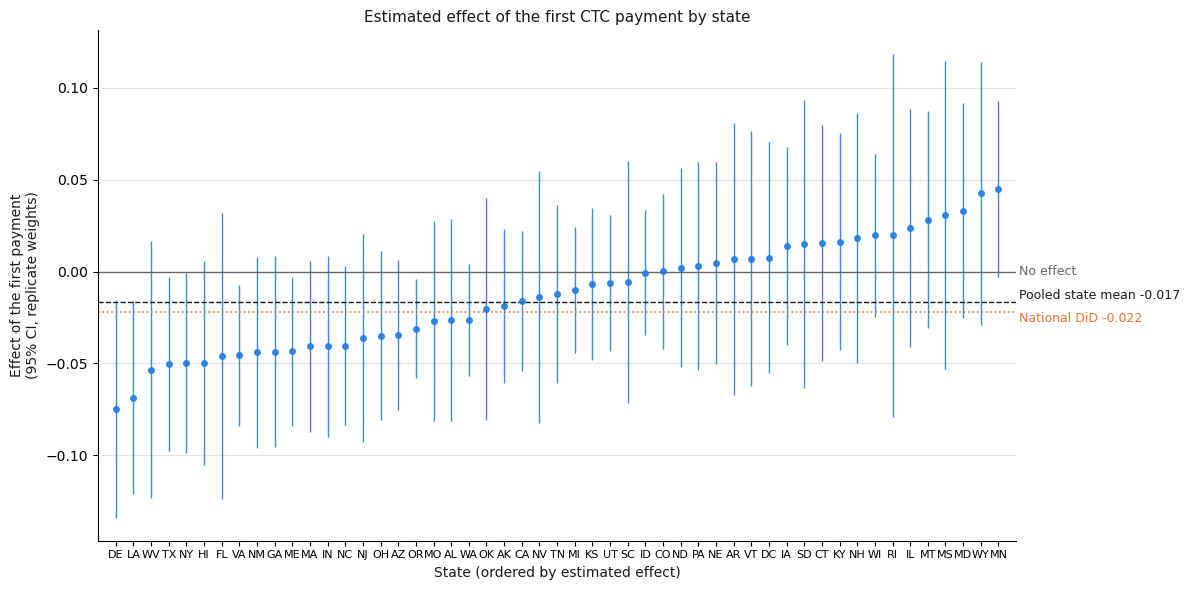

In [25]:
s = states.sort_values("effect").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(s))

ax.errorbar(x, s.effect, yerr=[s.effect - s.lo, s.hi - s.effect], fmt="o", ms=4,
            color=BLUE, ecolor=BLUE, elinewidth=1, capsize=0, alpha=0.9)

# Reference lines
pooled, national = het["re_mean"], did.params["kids_post"]
ax.axhline(0, color=MUTED, lw=1)
ax.axhline(pooled, color=INK, lw=1, ls="--")
ax.axhline(national, color=ORANGE, lw=1.2, ls=":")

# Labels just past the right edge; pooled (less negative) above its line, national below
x_lab = len(s) - 0.3
ax.text(x_lab, pooled, f"  Pooled state mean {pooled:.3f}", color=INK, fontsize=9,
        ha="left", va="bottom", clip_on=False)
ax.text(x_lab, national, f"  National DiD {national:.3f}", color=ORANGE, fontsize=9,
        ha="left", va="top", clip_on=False)
ax.text(x_lab, 0, "  No effect", color=MUTED, fontsize=9, ha="left", va="center", clip_on=False)

ax.set_xlim(-1, len(s))
ax.set_xticks(x, s.abbr, fontsize=8)
ax.set_xlabel("State (ordered by estimated effect)", color=INK)
ax.set_ylabel("Effect of the first payment\n(95% CI, replicate weights)", color=INK)
ax.set_title("Estimated effect of the first CTC payment by state", loc="center", color=INK, fontsize=11)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "state_effects.png", dpi=300, bbox_inches="tight")
plt.show()

State estimates rest on far fewer respondents than the national estimate (see `n_kids_wk34`, the households with children observed in week 34 in each state), so individual state confidence intervals are wide. Cochran's Q accounts for this: it asks whether the spread across states exceeds what those standard errors would produce by chance.

**Interpretation (a).** Hypothesis (a) is not supported: there is no statistical evidence that the effect of the first payment differed across states (Cochran's Q = 58.4 on 50 df, p = .19). The estimated standard deviation of true state effects is $\tau$ = 0.010, and $I^2$ = 14%: most of the visible spread in the chart is consistent with sampling error.

- **Low power.** Each state's standard error (0.013 to 0.050) is larger than the estimated $\tau$, so the test can detect only large differences between states. The result means no detectable variation, not evidence that the effect was identical everywhere; a spread of about 1 percentage point around a 2-point average cannot be ruled out.
- **The average effect is clearly negative.** Seven states have confidence intervals entirely below zero (DE, LA, TX, NY, VA, ME, OR) and none entirely above, more than chance alone would produce if the true effect were zero everywhere.
- **Individual states should not be ranked.** The states at the extremes of the chart are where estimates are noisiest; with no detectable heterogeneity, every state is consistent with a common effect.
- **The pooled mean (-0.017) is smaller than the national DiD (-0.022)** because it weights states by the precision of their estimates rather than by population, and because the state model gives each state its own gap between households with and without children.

### A note on survey weights

The unweighted DiD with state fixed effects (below) is about a third of the weighted estimate. The survey weights give more influence to groups that respond less often, such as lower-income and less-educated households. A much larger weighted effect means the payment's association with lower food insufficiency was concentrated in those underrepresented groups, and it is why the state analysis above keeps the weights.

In [26]:
fe_unw = ext.fit_fe_unweighted(a)
print(f"Unweighted fixed-effects DiD: {fe_unw.params['kids_post']:.4f} (SE {fe_unw.bse['kids_post']:.4f})   "
      f"[weighted, for reference: {did.params['kids_post']:.4f}]")

Unweighted fixed-effects DiD: -0.0069 (SE 0.0032)   [weighted, for reference: -0.0221]


## Appendix: mixed-model attempt

The proposal specified a linear mixed model (state random intercept + random slope on `kids_post`) compared with a random-intercept model by a likelihood-ratio test. Fit with statsmodels `MixedLM` on 585,170 rows, both a correlated and an independent random-slope specification produced singular random-effects covariance matrices and boundary warnings. The correlated specification gave an infinite likelihood-ratio statistic, and the independent one gave log-likelihoods of +135 (random slope) and +inf (random intercept), where a value near -125,000 is expected for this outcome and sample size. The LR test could not be computed, and the mixed models' estimates were not used. `MixedLM` also cannot use survey weights. The two-stage approach above tests the same null hypothesis (no between-state variance in the effect) with the survey weights and design-based standard errors.

## Summary of extensions

| Extension | Hypothesis | Result |
|---|---|---|
| (b) Replicate-weight SEs | $\beta_{34}$ remains significant | **Supported**: $\beta_{34}$ = -0.037, p < .001 (80 df); replicate SEs are 6-7% larger than state-clustered SEs |
| (a) State heterogeneity | Effect varies across states ($\tau^2$ > 0) | **Not supported**: Q = 58.4 on 50 df, p = .19; $\tau$ = 0.010, $I^2$ = 14% |

**Findings beyond the hypotheses:**

1. **The pre-trend finding depends on the variance method.** Parallel trends is rejected with state-clustered errors (p = .001) but not with replicate weights (p = .097), likely because cluster-robust joint tests over-reject with many restrictions and few clusters. The evidence against parallel trends is weaker than the replication alone suggested.
2. **Survey weights matter.** The unweighted DiD (-0.007) is about a third of the weighted estimate (-0.022), indicating that the association between the payment and lower food insufficiency was concentrated in groups that respond to the survey less often and receive larger weights, such as lower-income households.
3. **The planned mixed model could not be estimated reliably** with statsmodels at this sample size (see the appendix); the two-stage approach tests the same hypothesis with survey weights and design-based standard errors.